In [2]:
import pandas as pd
df= pd.read_csv(r"C:\Users\it\Downloads\customer_shopping_behavior.csv")

In [3]:
df.head()

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer ID             3900 non-null   int64  
 1   Age                     3900 non-null   int64  
 2   Gender                  3900 non-null   object 
 3   Item Purchased          3900 non-null   object 
 4   Category                3900 non-null   object 
 5   Purchase Amount (USD)   3900 non-null   int64  
 6   Location                3900 non-null   object 
 7   Size                    3900 non-null   object 
 8   Color                   3900 non-null   object 
 9   Season                  3900 non-null   object 
 10  Review Rating           3863 non-null   float64
 11  Subscription Status     3900 non-null   object 
 12  Shipping Type           3900 non-null   object 
 13  Discount Applied        3900 non-null   object 
 14  Promo Code Used         3900 non-null   

In [4]:
df.describe(include = 'all')

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
count,3900.000000,3900.000000,3900,3900,3900,3900.000000,3900,3900,3900,3900,3863.000000,3900,3900,3900,3900,3900.000000,3900,3900
unique,NaN,NaN,2,25,4,NaN,50,4,25,4,NaN,2,6,2,2,NaN,6,7
top,NaN,NaN,Male,Blouse,Clothing,NaN,Montana,M,Olive,Spring,NaN,No,Free Shipping,No,No,NaN,PayPal,Every 3 Months
freq,NaN,NaN,2652,171,1737,NaN,96,1755,177,999,NaN,2847,675,2223,2223,NaN,677,584
mean,1950.500000,44.068462,NaN,NaN,NaN,59.764359,NaN,NaN,NaN,NaN,3.750065,NaN,NaN,NaN,NaN,25.351538,NaN,NaN
std,1125.977353,15.207589,NaN,NaN,NaN,23.685392,NaN,NaN,NaN,NaN,0.716983,NaN,NaN,NaN,NaN,14.447125,NaN,NaN
min,1.000000,18.000000,NaN,NaN,NaN,20.000000,NaN,NaN,NaN,NaN,2.500000,NaN,NaN,NaN,NaN,1.000000,NaN,NaN
25%,975.750000,31.000000,NaN,NaN,NaN,39.000000,NaN,NaN,NaN,NaN,3.100000,NaN,NaN,NaN,NaN,13.000000,NaN,NaN
50%,1950.500000,44.000000,NaN,NaN,NaN,60.000000,NaN,NaN,NaN,NaN,3.800000,NaN,NaN,NaN,NaN,25.000000,NaN,NaN
75%,2925.250000,57.000000,NaN,NaN,NaN,81.000000,NaN,NaN,NaN,NaN,4.400000,NaN,NaN,NaN,NaN,38.000000,NaN,NaN


In [5]:
df.isnull().sum()

Customer ID                0
Age                        0
Gender                     0
Item Purchased             0
Category                   0
Purchase Amount (USD)      0
Location                   0
Size                       0
Color                      0
Season                     0
Review Rating             37
Subscription Status        0
Shipping Type              0
Discount Applied           0
Promo Code Used            0
Previous Purchases         0
Payment Method             0
Frequency of Purchases     0
dtype: int64

In [6]:
df['Review Rating'] = df.groupby('Category')['Review Rating'].transform(lambda x: x.fillna(x.median()))

In [7]:
df.isnull().sum()

Customer ID               0
Age                       0
Gender                    0
Item Purchased            0
Category                  0
Purchase Amount (USD)     0
Location                  0
Size                      0
Color                     0
Season                    0
Review Rating             0
Subscription Status       0
Shipping Type             0
Discount Applied          0
Promo Code Used           0
Previous Purchases        0
Payment Method            0
Frequency of Purchases    0
dtype: int64

In [8]:
df.columns = df.columns.str.lower().str.replace(' ','_')

In [9]:
df.columns

Index(['customer_id', 'age', 'gender', 'item_purchased', 'category',
       'purchase_amount_(usd)', 'location', 'size', 'color', 'season',
       'review_rating', 'subscription_status', 'shipping_type',
       'discount_applied', 'promo_code_used', 'previous_purchases',
       'payment_method', 'frequency_of_purchases'],
      dtype='object')

In [10]:
df = df.rename(columns ={ 'purchase_amount_(usd)':'purchase_amount'})

In [11]:
#create a column age_group
labels = ['Young adult', 'Adult', 'Middle Age', 'Senior']

df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 18, 35, 55, float('inf')],
    labels=labels
)

In [12]:
df[['age', 'age_group']].head(10)

,age,age_group
0,55,Middle Age
1,19,Adult
2,50,Middle Age
3,21,Adult
4,45,Middle Age
5,46,Middle Age
6,63,Senior
7,27,Adult
8,26,Adult
9,57,Senior


In [13]:
#create puchase_frequency_days
frequency_mapping = {
    'Fortnightly' : 14,
    'Weekly' : 7,
    'Monthly' : 30,
    'Quarterly' : 90,
    'Bi-Weekly' : 14,
    'Annually' : 365,
    'Every 3 Months' : 90
}
   
df['purchase_frequency_days'] = df['frequency_of_purchases'].map(frequency_mapping)





In [14]:
df[['purchase_frequency_days','frequency_of_purchases']].head(10)
                                                            

,purchase_frequency_days,frequency_of_purchases
0,14,Fortnightly
1,14,Fortnightly
2,7,Weekly
3,7,Weekly
4,365,Annually
5,7,Weekly
6,90,Quarterly
7,7,Weekly
8,365,Annually
9,90,Quarterly


In [15]:
df = df.drop('promo_code_used',axis=1)

In [16]:
df['gender'].value_counts()

gender
Male      2652
Female    1248
Name: count, dtype: int64

In [17]:
df['age'].describe()

count    3900.000000
mean       44.068462
std        15.207589
min        18.000000
25%        31.000000
50%        44.000000
75%        57.000000
max        70.000000
Name: age, dtype: float64

In [18]:
df['category'].value_counts()

category
Clothing       1737
Accessories    1240
Footwear        599
Outerwear       324
Name: count, dtype: int64

In [19]:
df['purchase_amount'].describe()

count    3900.000000
mean       59.764359
std        23.685392
min        20.000000
25%        39.000000
50%        60.000000
75%        81.000000
max       100.000000
Name: purchase_amount, dtype: float64

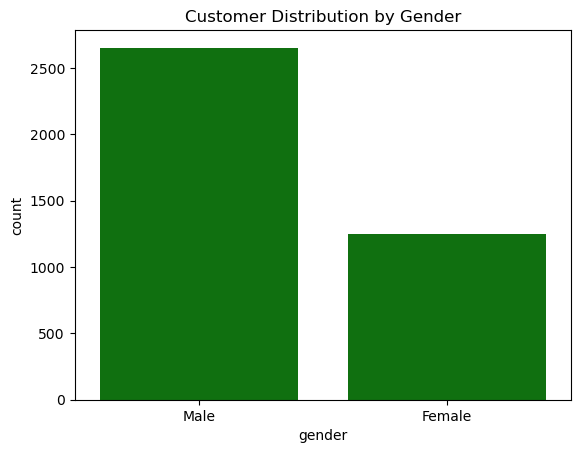

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x='gender',  color='green')
plt.title('Customer Distribution by Gender')
plt.show()

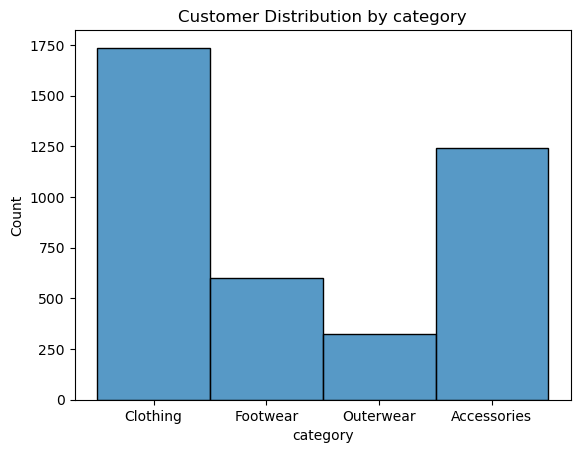

In [21]:
sns.histplot(data=df, x='category')
plt.title('Customer Distribution by category')
plt.show()

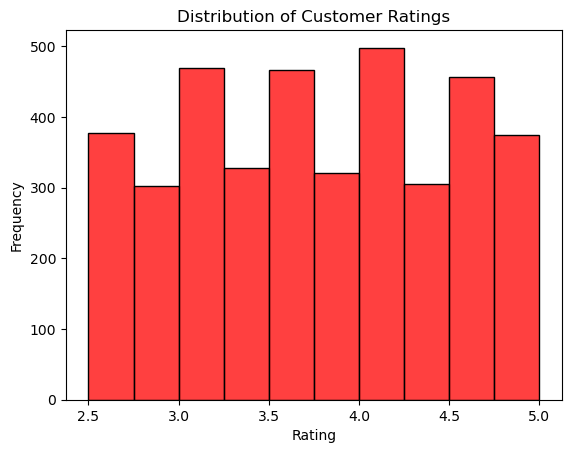

In [22]:
sns.histplot(data=df, x='review_rating', bins=10, color='red')

plt.title('Distribution of Customer Ratings')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.show()

In [23]:
df['review_rating'].mean()

np.float64(3.750051282051282)

In [24]:
df["category"].value_counts()

category
Clothing       1737
Accessories    1240
Footwear        599
Outerwear       324
Name: count, dtype: int64

In [25]:
df['age_group'].value_counts()

age_group
Middle Age     1482
Adult          1244
Senior         1105
Young adult      69
Name: count, dtype: int64

In [26]:
df.groupby('category')['purchase_amount'].mean().sort_values(ascending=False)

category
Footwear       60.255426
Clothing       60.025331
Accessories    59.838710
Outerwear      57.172840
Name: purchase_amount, dtype: float64

Business Findings and Conclusionsm -

Customer satisfaction: The average rating is 3.75 out of 5.
Popular category: Category "Clothing" has the highest number of purchases.
Spending behavior: Category "Footwear" has the highest average purchase amount.
Customer demographics: The Middle age group has the most transactions.

In [28]:
df.to_csv('customer_shopping_behavior_cleaned.csv', index=False)

In [29]:
import os

os.getcwd()

'C:\\Users\\it'

In [30]:
os.path.exists('customer_shopping_behavior_cleaned.csv')

True

In [27]:
df.isnull().sum()

customer_id                0
age                        0
gender                     0
item_purchased             0
category                   0
purchase_amount            0
location                   0
size                       0
color                      0
season                     0
review_rating              0
subscription_status        0
shipping_type              0
discount_applied           0
previous_purchases         0
payment_method             0
frequency_of_purchases     0
age_group                  0
purchase_frequency_days    0
dtype: int64

In [25]:
df[df['purchase_frequency_days'].isnull()]

,customer_id,age,gender,item_purchased,category,purchase_amount,location,size,color,season,review_rating,subscription_status,shipping_type,discount_applied,previous_purchases,payment_method,frequency_of_purchases,age_group,purchase_frequency_days
